
# Unemployment Analysis with Python

## Project Overview
Unemployment is an important economic indicator that reflects the availability of jobs and the condition of the labour market. This project explores unemployment trends across different regions of India, with particular attention to changes during the COVID-19 pandemic.

Using Python, pandas, Matplotlib, and Seaborn, this project analyses unemployment rates, employment estimates, and labour participation rates to identify regional differences and changes over time.

## Objective
The main objective is to perform exploratory data analysis (EDA) on unemployment data in India to understand regional and temporal patterns and examine how unemployment rates differed before and after the COVID-19 pandemic began.

## Dataset
The project uses the publicly available "Unemployment in India" dataset from Kaggle. The dataset contains observations for different Indian regions over time and includes measures related to unemployment, employment, and labour force participation.

## Technologies Used
- Python
- Jupyter Notebook
- pandas
- NumPy
- Matplotlib
- Seaborn

## Project Workflow
1. Introduce the project and load the dataset.
2. Inspect the dataset structure, data types, and data quality.
3. Clean and prepare the data for analysis.
4. Explore regional averages and monthly unemployment trends.
5. Visualise state-wise trends, the ten states with the highest average unemployment rates, and correlations between key indicators.
6. Compare average unemployment rates before and after the start of the COVID-19 pandemic.
7. Summarise the findings, limitations, and possible improvements.



## 1. Introduction

Unemployment analysis helps us understand how employment conditions vary across regions and change over time. Studying these patterns can highlight periods of rising unemployment and differences between regional labour markets.

The COVID-19 pandemic began affecting economic activity in India in 2020. Comparing unemployment data before and after this period can help us examine how the recorded unemployment rate changed around the pandemic.

In this project, exploratory data analysis will be used to investigate these patterns through summary statistics, tables, and visualisations.


In [1]:
# Import libraries for data analysis and visualisation
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set the visual style for charts
sns.set_style("whitegrid")

# Display plots inside the notebook
%matplotlib inline

# Confirm that the libraries have been imported
print("Libraries imported successfully.")

Libraries imported successfully.



### Data Loading and Initial Inspection

The dataset is the foundation of this analysis. Before performing calculations or creating visualisations, it is necessary to load the data and examine its structure.

The initial inspection will help identify the available columns, the number of observations, the data types, and any potential data-quality issues that may need to be addressed before analysis.


In [3]:
# Load the unemployment dataset
df = pd.read_csv(r"C:\Users\niles\OneDrive\Desktop\OIBSIP-DataScience-Task2-Unemployment-Analysis\Unemployment in India.csv")

# Display the first five rows
df.head()

,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


In [4]:
# Display the number of rows and columns
print("Dataset shape:", df.shape)

# Display all column names
print("\nColumn names:")
print(df.columns.tolist())

# Display dataset information, including data types and non-null counts
print("\nDataset information:")
df.info()

Dataset shape: (768, 7)

Column names:
['Region', ' Date', ' Frequency', ' Estimated Unemployment Rate (%)', ' Estimated Employed', ' Estimated Labour Participation Rate (%)', 'Area']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 7 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   Region                                    740 non-null    str    
 1    Date                                     740 non-null    str    
 2    Frequency                                740 non-null    str    
 3    Estimated Unemployment Rate (%)          740 non-null    float64
 4    Estimated Employed                       740 non-null    float64
 5    Estimated Labour Participation Rate (%)  740 non-null    float64
 6   Area                                      740 non-null    str    
dtypes: float64(3), str(4)
memory usage: 66.1 KB


In [5]:
# Count missing values in each column
print("Missing values by column:")
print(df.isnull().sum())

# Count duplicate rows
print("\nNumber of duplicate rows:", df.duplicated().sum())

# Display descriptive statistics for numeric columns
print("\nDescriptive statistics:")
display(df.describe())

Missing values by column:
Region                                      28
 Date                                       28
 Frequency                                  28
 Estimated Unemployment Rate (%)            28
 Estimated Employed                         28
 Estimated Labour Participation Rate (%)    28
Area                                        28
dtype: int64

Number of duplicate rows: 27

Descriptive statistics:


,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%)
count,740.000000,7.400000e+02,740.000000
mean,11.787946,7.204460e+06,42.630122
std,10.721298,8.087988e+06,8.111094
min,0.000000,4.942000e+04,13.330000
25%,4.657500,1.190404e+06,38.062500
50%,8.350000,4.744178e+06,41.160000
75%,15.887500,1.127549e+07,45.505000
max,76.740000,4.577751e+07,72.570000


### Initial Data Inspection — Observations

- The dataset contains 768 rows and 7 columns.
- Only 740 rows contain non-null values across the dataset, while 28 rows have missing values in every column.
- The dataset includes regional information, dates, reporting frequency, estimated unemployment rates, employment estimates, labour participation rates, and area classifications.
- The three numeric columns contain 740 valid observations each.
- The average unemployment rate across the available observations is approximately 11.79%, while the average labour participation rate is approximately 42.63%.
- The maximum recorded unemployment rate is 76.74%, indicating substantial variation in the dataset.
- The initial inspection identified 27 duplicate rows that require further examination.

These findings suggest that the dataset needs cleaning before reliable regional and time-based comparisons can be performed.



## 2. Data Cleaning and Preparation

Before analyzing unemployment trends, the dataset must be cleaned to ensure that the results are reliable.

The initial inspection identified 28 rows with missing values across all columns and 27 duplicate rows. Some column names also contain leading or trailing spaces.

The following steps will be performed:

1. Remove unnecessary spaces from column names and text values.
2. Convert the date column into a proper datetime format.
3. Ensure that numerical columns contain numeric values.
4. Recheck missing values, duplicate records, and data types.
5. Remove completely empty rows and exact duplicate records.
6. Verify the final cleaned dataset before beginning exploratory data analysis.


In [6]:

# Clean column names by removing leading and trailing spaces
df.columns = df.columns.str.strip()

# Clean text columns by removing unnecessary spaces
text_columns = ["Region", "Date", "Frequency", "Area"]

for column in text_columns:
    df[column] = df[column].astype("string").str.strip()

    # Convert empty strings into missing values
    df[column] = df[column].replace("", pd.NA)

# Display the cleaned column names
print("Cleaned column names:")
print(df.columns.tolist())

# Display the first five rows
df.head()


Cleaned column names:
['Region', 'Date', 'Frequency', 'Estimated Unemployment Rate (%)', 'Estimated Employed', 'Estimated Labour Participation Rate (%)', 'Area']


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


In [7]:

# Convert the Date column into datetime format
df["Date"] = pd.to_datetime(
    df["Date"],
    dayfirst=True,
    errors="coerce"
)

# Convert numerical columns into numeric data types
numeric_columns = [
    "Estimated Unemployment Rate (%)",
    "Estimated Employed",
    "Estimated Labour Participation Rate (%)"
]

for column in numeric_columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")

# Display the updated data types
print("Updated data types:")
print(df.dtypes)

# Display the first five rows
df.head()


Updated data types:
Region                                             string
Date                                       datetime64[us]
Frequency                                          string
Estimated Unemployment Rate (%)                   float64
Estimated Employed                                float64
Estimated Labour Participation Rate (%)           float64
Area                                               string
dtype: object


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,2019-05-31,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,2019-06-30,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,2019-07-31,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,2019-08-31,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,2019-09-30,Monthly,5.17,12256762.0,44.68,Rural


In [8]:

# Count missing values in each column
print("Missing values after conversion:")
print(df.isna().sum())

# Count rows that are completely empty
print("\nCompletely empty rows:")
print(df.isna().all(axis=1).sum())

# Count exact duplicate rows
print("\nDuplicate rows:")
print(df.duplicated().sum())

# Display data types and non-null counts
print("\nDataset information:")
df.info()


Missing values after conversion:
Region                                     28
Date                                       28
Frequency                                  28
Estimated Unemployment Rate (%)            28
Estimated Employed                         28
Estimated Labour Participation Rate (%)    28
Area                                       28
dtype: int64

Completely empty rows:
28

Duplicate rows:
27

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 7 columns):
 #   Column                                   Non-Null Count  Dtype         
---  ------                                   --------------  -----         
 0   Region                                   740 non-null    string        
 1   Date                                     740 non-null    datetime64[us]
 2   Frequency                                740 non-null    string        
 3   Estimated Unemployment Rate (%)          740 non-null    float64       
 4   Est

In [9]:

# Record the original number of rows
original_rows = len(df)

# Count and remove rows where every column is missing
empty_rows = df.isna().all(axis=1).sum()
df = df.dropna(how="all")

# Count and remove exact duplicate records
duplicate_rows = df.duplicated().sum()
df = df.drop_duplicates()

# Display cleaning results
print("Data cleaning summary")
print("---------------------")
print("Original number of rows:", original_rows)
print("Completely empty rows removed:", empty_rows)
print("Duplicate rows removed:", duplicate_rows)
print("Rows remaining:", len(df))

# Check for any remaining missing values
print("\nMissing values after removing empty rows and duplicates:")
print(df.isna().sum())

# Check the final number of duplicate rows
print("\nRemaining duplicate rows:", df.duplicated().sum())


Data cleaning summary
---------------------
Original number of rows: 768
Completely empty rows removed: 28
Duplicate rows removed: 0
Rows remaining: 740

Missing values after removing empty rows and duplicates:
Region                                     0
Date                                       0
Frequency                                  0
Estimated Unemployment Rate (%)            0
Estimated Employed                         0
Estimated Labour Participation Rate (%)    0
Area                                       0
dtype: int64

Remaining duplicate rows: 0




### Data Cleaning — Observations

- The original dataset contained 768 rows and 7 columns.
- Column names were standardized by removing unnecessary leading and trailing spaces.
- Text values were cleaned to remove extra whitespace, and blank strings were treated as missing values.
- The `Date` column was successfully converted into datetime format, while the numerical columns were retained as numeric data types.
- The initial inspection identified 28 completely empty rows. These rows were removed during cleaning.
- The initial duplicate count was 27; however, these duplicates were associated with the completely empty rows. After removing the empty rows, no duplicate records remained.
- The cleaned dataset contains 740 rows and 7 columns.
- All seven columns have zero missing values after cleaning.
- The final dataset contains no duplicate records.

The dataset is now clean and ready for exploratory data analysis. We can proceed to examine regional unemployment patterns, changes over time, and differences before and after the COVID-19 pandemic.



## 3. Exploratory Data Analysis (EDA)

Exploratory Data Analysis (EDA) helps us understand the patterns, distributions, and relationships present in a dataset before drawing conclusions.

In this section, we will:

1. Examine the cleaned dataset and its date range.
2. Identify the regions and reporting frequencies represented.
3. Calculate average unemployment rates by region.
4. Study how unemployment rates change over time.
5. Compare regions and examine relationships between numerical variables.
6. Investigate changes in unemployment before and after the COVID-19 pandemic.

The findings will help us understand regional differences and the impact of the pandemic on unemployment in India.


In [10]:

# Display the date range covered by the dataset
print("Earliest date:", df["Date"].min().date())
print("Latest date:", df["Date"].max().date())

# Count the number of unique regions
print("\nNumber of unique regions:", df["Region"].nunique())

# Display all regions in alphabetical order
print("\nRegions included in the dataset:")
print(sorted(df["Region"].unique()))

# Check reporting frequencies
print("\nReporting frequencies:")
print(df["Frequency"].value_counts())

# Check the distribution of rural and urban observations
print("\nArea distribution:")
print(df["Area"].value_counts())


Earliest date: 2019-05-31
Latest date: 2020-06-30

Number of unique regions: 28

Regions included in the dataset:
['Andhra Pradesh', 'Assam', 'Bihar', 'Chandigarh', 'Chhattisgarh', 'Delhi', 'Goa', 'Gujarat', 'Haryana', 'Himachal Pradesh', 'Jammu & Kashmir', 'Jharkhand', 'Karnataka', 'Kerala', 'Madhya Pradesh', 'Maharashtra', 'Meghalaya', 'Odisha', 'Puducherry', 'Punjab', 'Rajasthan', 'Sikkim', 'Tamil Nadu', 'Telangana', 'Tripura', 'Uttar Pradesh', 'Uttarakhand', 'West Bengal']

Reporting frequencies:
Frequency
Monthly    740
Name: count, dtype: int64[pyarrow]

Area distribution:
Area
Urban    381
Rural    359
Name: count, dtype: int64[pyarrow]



### 3.1 Regional Unemployment Analysis

Unemployment rates can vary considerably between regions due to differences in economic activity, employment opportunities, and local conditions.

In this analysis, we will calculate the average estimated unemployment rate for each region and identify regions with relatively high and low average unemployment rates. These averages will help us compare regional differences across the period covered by the dataset.


In [11]:

# Calculate the average unemployment rate for each region
regional_unemployment = (
    df.groupby("Region")["Estimated Unemployment Rate (%)"]
    .mean()
    .sort_values(ascending=False)
)

# Display the average unemployment rate for every region
print("Average Unemployment Rate by Region:")
print(regional_unemployment.round(2))

# Display the five regions with the highest averages
print("\nFive regions with the highest average unemployment rates:")
print(regional_unemployment.head(5).round(2))

# Display the five regions with the lowest averages
print("\nFive regions with the lowest average unemployment rates:")
print(regional_unemployment.tail(5).round(2))


Average Unemployment Rate by Region:
Region
Tripura             28.35
Haryana             26.28
Jharkhand           20.58
Bihar               18.92
Himachal Pradesh    18.54
Delhi               16.50
Jammu & Kashmir     16.19
Chandigarh          15.99
Rajasthan           14.06
Uttar Pradesh       12.55
Punjab              12.03
Puducherry          10.22
Kerala              10.12
Tamil Nadu           9.28
Goa                  9.27
Chhattisgarh         9.24
West Bengal          8.12
Telangana            7.74
Maharashtra          7.56
Andhra Pradesh       7.48
Madhya Pradesh       7.41
Sikkim               7.25
Karnataka            6.68
Gujarat              6.66
Uttarakhand          6.58
Assam                6.43
Odisha               5.66
Meghalaya            4.80
Name: Estimated Unemployment Rate (%), dtype: float64

Five regions with the highest average unemployment rates:
Region
Tripura             28.35
Haryana             26.28
Jharkhand           20.58
Bihar               18.92
Hima

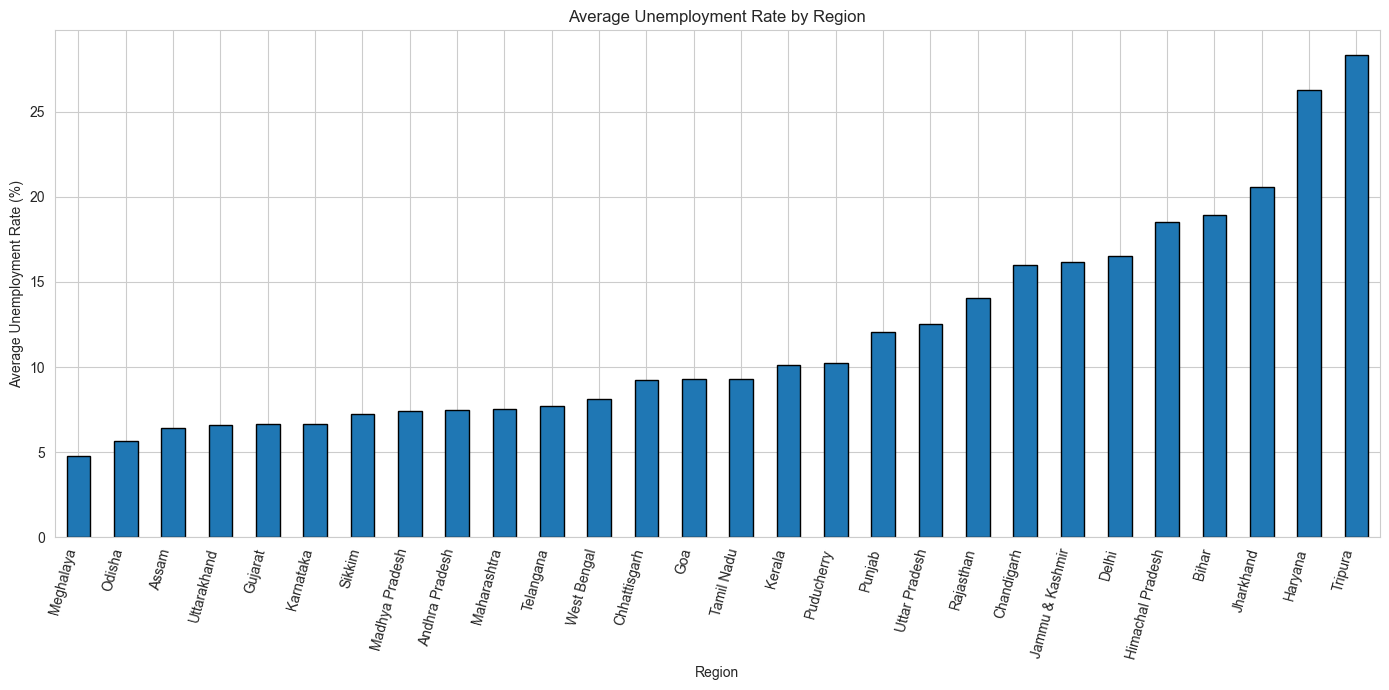

In [12]:

# Create a bar chart of average unemployment rates by region
plt.figure(figsize=(14, 7))

regional_unemployment.sort_values().plot(
    kind="bar",
    edgecolor="black"
)

plt.title("Average Unemployment Rate by Region")
plt.xlabel("Region")
plt.ylabel("Average Unemployment Rate (%)")
plt.xticks(rotation=75, ha="right")
plt.tight_layout()
plt.show()



### 3.2 Regions with the Highest Average Unemployment Rates

Identifying regions with the highest average unemployment rates helps highlight where unemployment was comparatively elevated during the study period.

We will rank the ten regions with the highest average unemployment rates and visualize them using a bar chart.


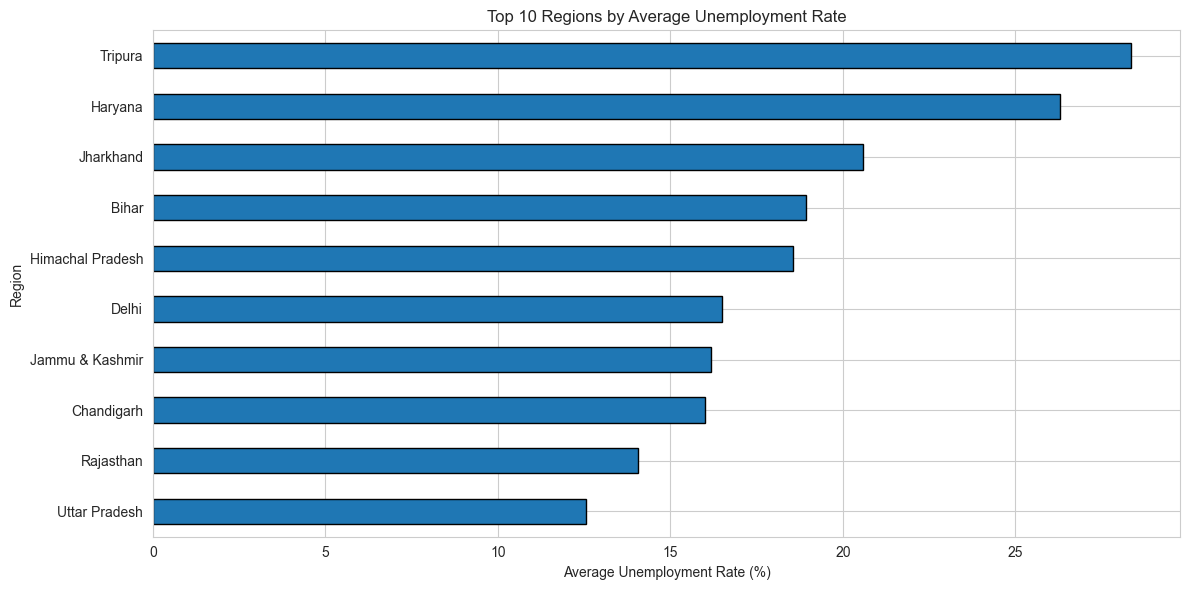

Top 10 regions by average unemployment rate:
Region
Tripura             28.35
Haryana             26.28
Jharkhand           20.58
Bihar               18.92
Himachal Pradesh    18.54
Delhi               16.50
Jammu & Kashmir     16.19
Chandigarh          15.99
Rajasthan           14.06
Uttar Pradesh       12.55
Name: Estimated Unemployment Rate (%), dtype: float64


In [13]:

# Select the ten regions with the highest average unemployment rates
top_10_regions = regional_unemployment.head(10).sort_values()

# Plot the top ten regions
plt.figure(figsize=(12, 6))

top_10_regions.plot(
    kind="barh",
    edgecolor="black"
)

plt.title("Top 10 Regions by Average Unemployment Rate")
plt.xlabel("Average Unemployment Rate (%)")
plt.ylabel("Region")
plt.tight_layout()
plt.show()

# Display the exact values
print("Top 10 regions by average unemployment rate:")
print(regional_unemployment.head(10).round(2))



### Regional Unemployment Analysis — Observations

- The dataset covers 28 regions, and their average unemployment rates vary considerably.
- Tripura recorded the highest average unemployment rate at approximately 28.35%, followed by Haryana at 26.28%.
- Jharkhand, Bihar, and Himachal Pradesh also had relatively high average unemployment rates of 20.58%, 18.92%, and 18.54%, respectively.
- Meghalaya recorded the lowest average unemployment rate at approximately 4.80%, followed by Odisha at 5.66%.
- Assam, Uttarakhand, and Gujarat also had relatively low average unemployment rates, ranging from approximately 6.43% to 6.66%.
- The difference between Tripura's and Meghalaya's average unemployment rates was approximately 23.55 percentage points.
- These results indicate substantial regional variation in unemployment during the period covered by the dataset.

These averages describe the observed period from May 2019 to June 2020. They do not, by themselves, establish the reasons for the differences between regions.



### 3.3 Monthly Unemployment Trends

Examining unemployment over time helps us identify periods when unemployment increased or decreased.

In this analysis, we will calculate the average unemployment rate for each month across all regions. We will then visualize the monthly trend to identify notable changes during the study period, including the period surrounding the COVID-19 pandemic.


In [14]:

# Calculate the average unemployment rate for each month
monthly_unemployment = (
    df.groupby("Date")["Estimated Unemployment Rate (%)"]
    .mean()
    .sort_index()
)

# Display the monthly average unemployment rates
print("Monthly Average Unemployment Rates:")
print(monthly_unemployment.round(2))


Monthly Average Unemployment Rates:
Date
2019-05-31     8.87
2019-06-30     9.30
2019-07-31     9.03
2019-08-31     9.64
2019-09-30     9.05
2019-10-31     9.90
2019-11-30     9.87
2019-12-31     9.50
2020-01-31     9.95
2020-02-29     9.96
2020-03-31    10.70
2020-04-30    23.64
2020-05-31    24.88
2020-06-30    11.90
Name: Estimated Unemployment Rate (%), dtype: float64


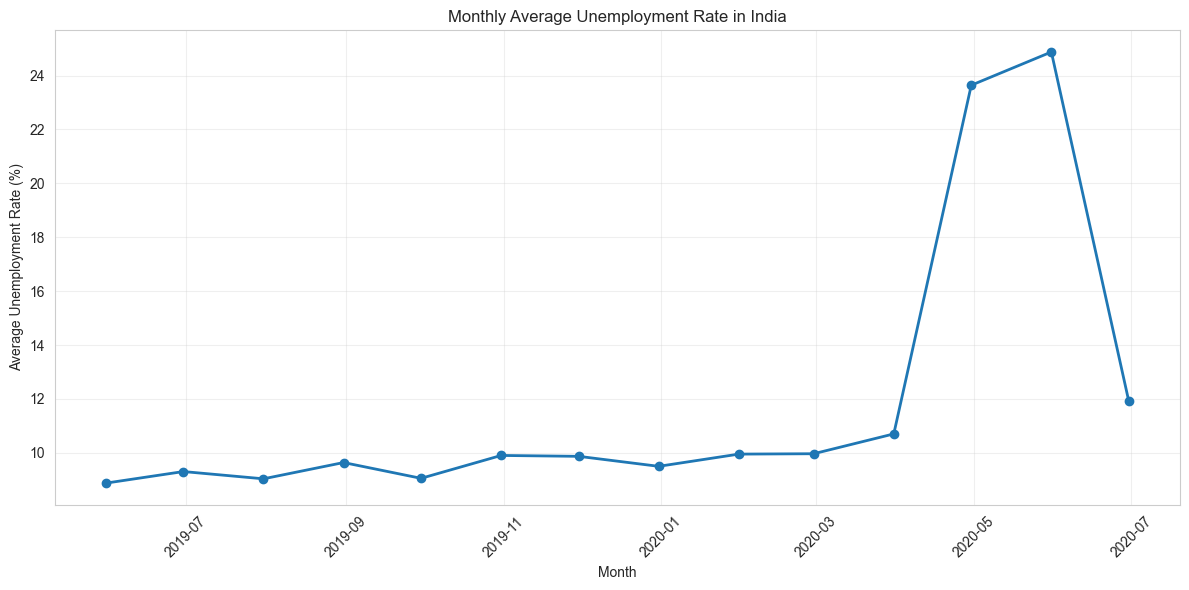

In [15]:

# Plot the monthly unemployment trend
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_unemployment.index,
    monthly_unemployment.values,
    marker="o",
    linewidth=2
)

plt.title("Monthly Average Unemployment Rate in India")
plt.xlabel("Month")
plt.ylabel("Average Unemployment Rate (%)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


Monthly Unemployment Rates for Selected Regions:
Region      Haryana  Maharashtra  Tamil Nadu
Date                                        
2019-05-31    19.60         4.88        0.93
2019-06-30    21.75         5.40        1.24
2019-07-31    20.84         5.00        4.60
2019-08-31    27.56         5.66        6.22
2019-09-30    21.60         6.00        1.78
2019-10-31    22.60         5.66        1.30
2019-11-30    21.82         5.64        2.55
2019-12-31    26.60         5.43        5.89
2020-01-31    21.72         5.24        1.61
2020-02-29    25.24         4.79        2.24
2020-03-31    25.53         5.86        6.41
2020-04-30    44.25        20.14       49.37
2020-05-31    36.34        16.40       32.34
2020-06-30    32.49         9.70       13.50


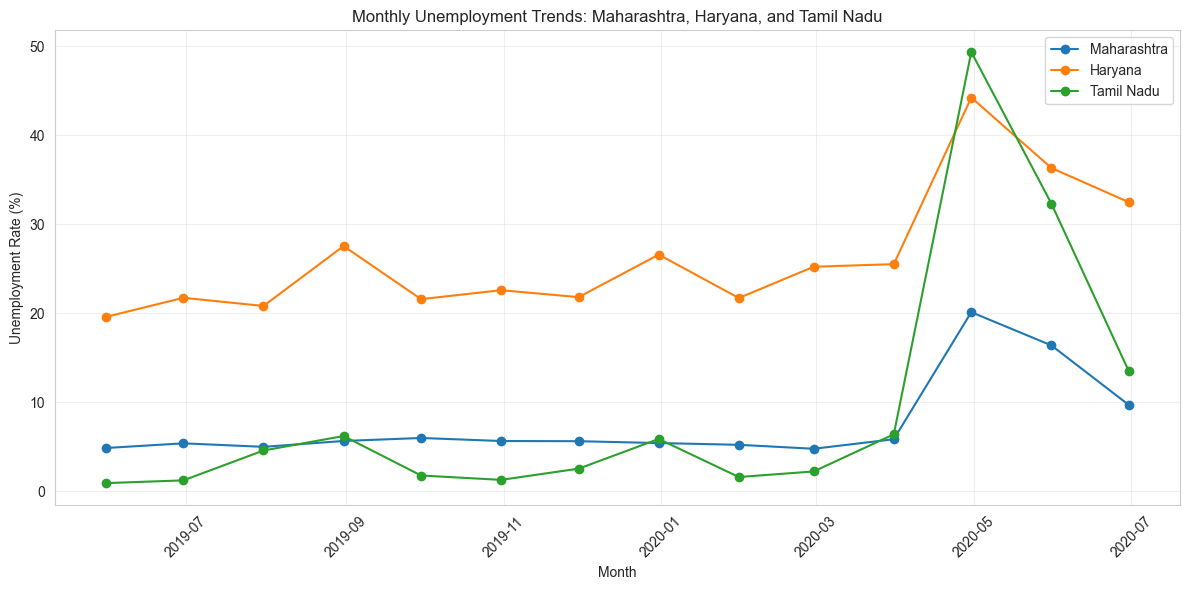

In [16]:

# Select three regions for time-series comparison
selected_regions = ["Maharashtra", "Haryana", "Tamil Nadu"]

# Calculate monthly unemployment rates for the selected regions
state_trends = (
    df[df["Region"].isin(selected_regions)]
    .groupby(["Date", "Region"])["Estimated Unemployment Rate (%)"]
    .mean()
    .unstack()
    .sort_index()
)

# Display the monthly values
print("Monthly Unemployment Rates for Selected Regions:")
print(state_trends.round(2))

# Plot the time-series comparison
plt.figure(figsize=(12, 6))

for region in selected_regions:
    plt.plot(
        state_trends.index,
        state_trends[region],
        marker="o",
        label=region
    )

plt.title("Monthly Unemployment Trends: Maharashtra, Haryana, and Tamil Nadu")
plt.xlabel("Month")
plt.ylabel("Unemployment Rate (%)")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()



### Monthly Unemployment Trends — Observations

- The average unemployment rate fluctuated between approximately 8.87% and 9.96% from May 2019 through February 2020.
- The monthly average increased to 10.70% in March 2020, followed by a sharp rise to 23.64% in April 2020.
- The highest monthly average in the dataset occurred in May 2020, at approximately 24.88%.
- By June 2020, the monthly average had declined to 11.90%, indicating a substantial reduction from the April and May peaks.
- Among the three selected regions, Haryana generally recorded higher unemployment rates than Maharashtra and Tamil Nadu before April 2020.
- In April 2020, unemployment rates rose sharply in all three regions: 44.25% in Haryana, 20.14% in Maharashtra, and 49.37% in Tamil Nadu.
- By June 2020, the rates had declined to 32.49% in Haryana, 9.70% in Maharashtra, and 13.50% in Tamil Nadu.
- The timing of the sharp increase coincides with the early COVID-19 period. However, these observations show a temporal association and do not independently establish causation.

Overall, the data highlights a pronounced rise in unemployment during April and May 2020, followed by a partial decline in June 2020.



### 3.4 Correlation Between Employment Indicators

Correlation analysis helps us examine the relationships between the estimated unemployment rate, estimated number of employed people, and estimated labour participation rate.

Correlation coefficients range from -1 to +1. Positive values indicate that two variables tend to increase together, while negative values indicate that one tends to decrease as the other increases. Values closer to zero indicate weaker linear relationships.

Correlation does not establish causation, and these relationships should be interpreted in the context of the dataset.


In [19]:

# Select numerical variables for correlation analysis
employment_variables = [
    "Estimated Unemployment Rate (%)",
    "Estimated Employed",
    "Estimated Labour Participation Rate (%)"
]

# Calculate and display the correlation matrix
correlation_matrix = df[employment_variables].corr()

print("Correlation Matrix:")
print(correlation_matrix.round(3))


Correlation Matrix:
                                         Estimated Unemployment Rate (%)  \
Estimated Unemployment Rate (%)                                    1.000   
Estimated Employed                                                -0.223   
Estimated Labour Participation Rate (%)                            0.003   

                                         Estimated Employed  \
Estimated Unemployment Rate (%)                      -0.223   
Estimated Employed                                    1.000   
Estimated Labour Participation Rate (%)               0.011   

                                         Estimated Labour Participation Rate (%)  
Estimated Unemployment Rate (%)                                            0.003  
Estimated Employed                                                         0.011  
Estimated Labour Participation Rate (%)                                    1.000  




### Correlation Analysis — Observations

- The correlation between the estimated unemployment rate and estimated employment was approximately **-0.223**, indicating a weak negative linear relationship in the dataset.
- The correlation between the estimated unemployment rate and labour participation rate was approximately **0.003**, indicating virtually no linear relationship between these variables across the observations.
- The correlation between estimated employment and labour participation rate was approximately **0.011**, also indicating virtually no linear relationship.
- These results suggest that the three variables do not show strong linear relationships with one another in this dataset. Correlation does not establish causation, and these overall coefficients may not capture differences across regions or months.



## 4. COVID-19 Impact Analysis

The COVID-19 pandemic coincided with significant changes in economic activity and employment conditions in India. This section compares unemployment rates before and during the early COVID-19 period using the available dataset.

For this analysis:
- **Pre-COVID period:** Observations dated before 1 March 2020.
- **COVID period:** Observations dated 1 March 2020 onward.

We will compare average unemployment rates across the two periods, examine changes by region, and visualize the differences. This is a descriptive comparison and does not independently establish that the pandemic caused the observed changes.


In [21]:

# Define the start of the COVID period for this analysis
covid_start_date = pd.Timestamp("2020-03-01")

# Assign each observation to a period
df["Period"] = df["Date"].apply(
    lambda date: "Pre-COVID"
    if date < covid_start_date
    else "COVID Period"
)

# Display the number of observations in each period
print("Number of observations in each period:")
print(df["Period"].value_counts())

# Display the date range covered by each period
print("\nDate ranges by period:")
print(
    df.groupby("Period")["Date"]
    .agg(["min", "max"])
    .reindex(["Pre-COVID", "COVID Period"])
)


Number of observations in each period:
Period
Pre-COVID       536
COVID Period    204
Name: count, dtype: int64

Date ranges by period:
                    min        max
Period                            
Pre-COVID    2019-05-31 2020-02-29
COVID Period 2020-03-31 2020-06-30


In [22]:

# Calculate the average unemployment rate for each period
period_comparison = (
    df.groupby("Period")["Estimated Unemployment Rate (%)"]
    .mean()
    .reindex(["Pre-COVID", "COVID Period"])
)

print("Average unemployment rate by period:")
print(period_comparison.round(2))

# Calculate the absolute change in percentage points
absolute_change = (
    period_comparison["COVID Period"]
    - period_comparison["Pre-COVID"]
)

print("\nChange in unemployment rate (percentage points):")
print(round(absolute_change, 2))

# Calculate the percentage change relative to the pre-COVID average
percentage_change = (
    absolute_change / period_comparison["Pre-COVID"]
) * 100

print("\nPercentage change relative to the pre-COVID average:")
print(round(percentage_change, 2), "%")


Average unemployment rate by period:
Period
Pre-COVID        9.51
COVID Period    17.77
Name: Estimated Unemployment Rate (%), dtype: float64

Change in unemployment rate (percentage points):
8.26

Percentage change relative to the pre-COVID average:
86.91 %


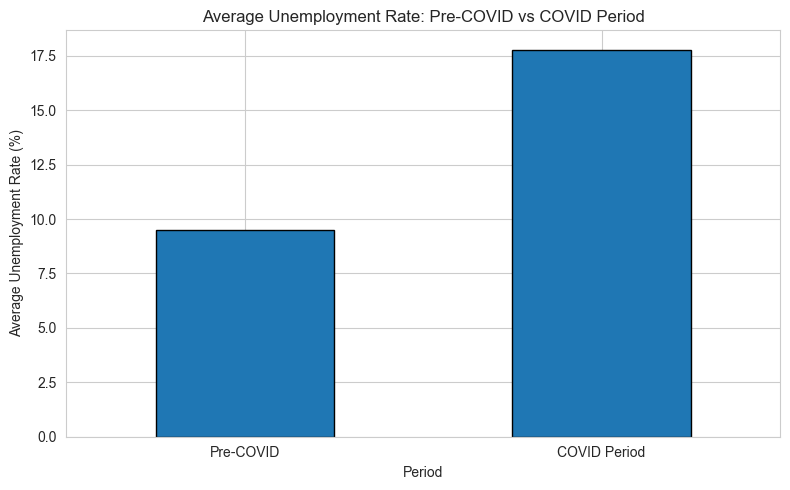

In [23]:

# Plot average unemployment rates for the two periods
plt.figure(figsize=(8, 5))

period_comparison.plot(
    kind="bar",
    edgecolor="black"
)

plt.title("Average Unemployment Rate: Pre-COVID vs COVID Period")
plt.xlabel("Period")
plt.ylabel("Average Unemployment Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [24]:

# Calculate regional averages for each period
regional_period_comparison = (
    df.groupby(["Region", "Period"])["Estimated Unemployment Rate (%)"]
    .mean()
    .unstack()
    .reindex(columns=["Pre-COVID", "COVID Period"])
)

# Calculate the change in percentage points for each region
regional_period_comparison["Change (percentage points)"] = (
    regional_period_comparison["COVID Period"]
    - regional_period_comparison["Pre-COVID"]
)

# Sort regions by the size of the increase
regional_period_comparison = regional_period_comparison.sort_values(
    by="Change (percentage points)",
    ascending=False
)

# Display results for all regions
print("Regional comparison: Pre-COVID vs COVID period")
print(regional_period_comparison.round(2))

# Display the five regions with the largest increases
print("\nFive regions with the largest increases:")
print(regional_period_comparison.head(5).round(2))

# Display the five regions with the smallest changes
print("\nFive regions with the smallest changes:")
print(regional_period_comparison.tail(5).round(2))


Regional comparison: Pre-COVID vs COVID period
Period            Pre-COVID  COVID Period  Change (percentage points)
Region                                                               
Puducherry             1.59         38.96                       37.36
Tamil Nadu             2.84         25.40                       22.57
Jharkhand             14.28         36.35                       22.07
Bihar                 13.83         31.63                       17.80
Karnataka              3.23         15.28                       12.05
Haryana               22.94         34.65                       11.72
Kerala                 6.99         17.95                       10.96
Telangana              4.66         15.44                       10.79
Madhya Pradesh         4.74         14.07                        9.33
Andhra Pradesh         5.04         13.58                        8.54
Delhi                 14.23         22.16                        7.93
Odisha                 3.41         11.28  

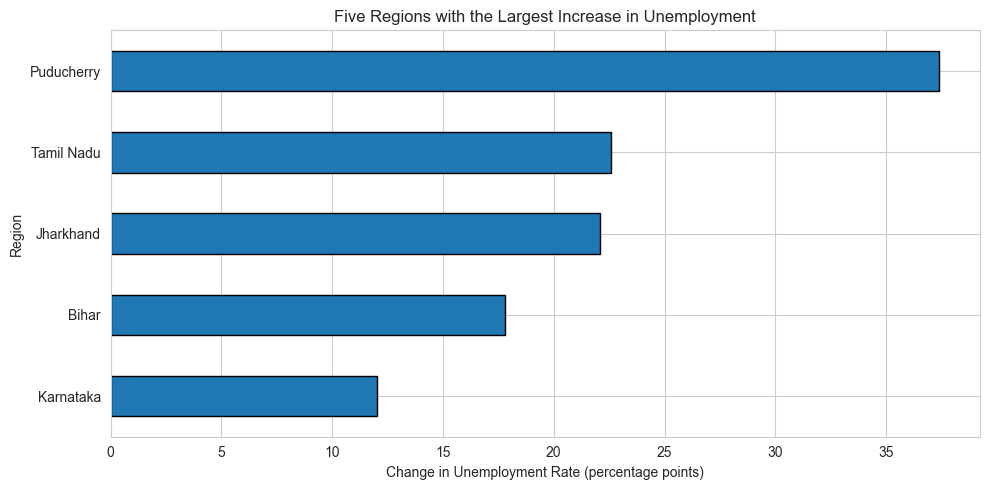

In [25]:

# Select the five regions with the largest increases
largest_increases = (
    regional_period_comparison.head(5)["Change (percentage points)"]
    .sort_values()
)

# Create a horizontal bar chart
plt.figure(figsize=(10, 5))

largest_increases.plot(
    kind="barh",
    edgecolor="black"
)

plt.title("Five Regions with the Largest Increase in Unemployment")
plt.xlabel("Change in Unemployment Rate (percentage points)")
plt.ylabel("Region")
plt.tight_layout()
plt.show()



### COVID-19 Impact Analysis — Observations

- The dataset contained **536 observations in the pre-COVID period** (May 2019–February 2020) and **204 observations in the COVID period** (March–June 2020).

- The average unemployment rate increased from **9.51% before COVID-19 to 17.77% during the COVID period**, an increase of **8.26 percentage points**, or approximately **86.91%** relative to the pre-COVID average.

- **Puducherry recorded the largest increase** in average unemployment, rising by 37.36 percentage points, from 1.59% to 38.96%. Tamil Nadu, Jharkhand, Bihar, and Karnataka followed with increases of 22.57, 22.07, 17.80, and 12.05 percentage points, respectively.

- **Assam showed almost no change**, with an increase of just 0.21 percentage points. Chandigarh, Himachal Pradesh, Tripura, and Jammu & Kashmir recorded decreases in their average unemployment rates during the COVID period.

- Overall, the results show a substantial rise in average unemployment during the early COVID-19 period, although the impact varied considerably across regions.

- This is a descriptive comparison of the available observations. The changes coincided with the pandemic but do not, by themselves, prove that COVID-19 caused every observed change. The COVID-period averages also cover only March–June 2020.



## 5. Final Summary and Conclusion

This section brings together the main findings from the unemployment analysis. It summarizes the dataset, identifies key unemployment patterns, and verifies the final dataset used in the project.

The conclusions are based on descriptive statistical analysis and visualizations. They highlight patterns in unemployment across regions and over time, including changes observed during the early COVID-19 period.


In [27]:

# Calculate key project summary statistics

overall_unemployment = df["Estimated Unemployment Rate (%)"].mean()
overall_employment = df["Estimated Employed"].mean()
overall_labour_participation = df[
    "Estimated Labour Participation Rate (%)"
].mean()

regional_averages = (
    df.groupby("Region")["Estimated Unemployment Rate (%)"]
    .mean()
    .sort_values(ascending=False)
)

monthly_averages = (
    df.groupby("Date")["Estimated Unemployment Rate (%)"]
    .mean()
    .sort_index()
)

highest_region = regional_averages.idxmax()
highest_region_rate = regional_averages.max()

lowest_region = regional_averages.idxmin()
lowest_region_rate = regional_averages.min()

peak_date = monthly_averages.idxmax()
peak_month_rate = monthly_averages.max()

print("FINAL PROJECT SUMMARY")
print("-" * 40)

print(f"Total observations: {len(df)}")
print(f"Number of regions: {df['Region'].nunique()}")
print(f"Date range: {df['Date'].min().date()} to {df['Date'].max().date()}")

print(f"\nOverall average unemployment rate: {overall_unemployment:.2f}%")
print(f"Average estimated employment: {overall_employment:,.0f}")
print(
    "Average labour participation rate: "
    f"{overall_labour_participation:.2f}%"
)

print(
    f"\nHighest average unemployment region: "
    f"{highest_region} ({highest_region_rate:.2f}%)"
)
print(
    f"Lowest average unemployment region: "
    f"{lowest_region} ({lowest_region_rate:.2f}%)"
)

print(
    f"\nHighest monthly average unemployment: "
    f"{peak_month_rate:.2f}% in {peak_date.strftime('%B %Y')}"
)


FINAL PROJECT SUMMARY
----------------------------------------
Total observations: 740
Number of regions: 28
Date range: 2019-05-31 to 2020-06-30

Overall average unemployment rate: 11.79%
Average estimated employment: 7,204,460
Average labour participation rate: 42.63%

Highest average unemployment region: Tripura (28.35%)
Lowest average unemployment region: Meghalaya (4.80%)

Highest monthly average unemployment: 24.88% in May 2020


In [28]:

# Verify the final dataset before completing the project

print("FINAL DATA QUALITY CHECK")
print("-" * 40)

print(f"Dataset shape: {df.shape}")

print("\nMissing values in each column:")
print(df.isnull().sum())

print(f"\nNumber of duplicate rows: {df.duplicated().sum()}")

print(f"\nInvalid dates: {df['Date'].isnull().sum()}")

print("\nData types:")
print(df.dtypes)


FINAL DATA QUALITY CHECK
----------------------------------------
Dataset shape: (740, 8)

Missing values in each column:
Region                                     0
Date                                       0
Frequency                                  0
Estimated Unemployment Rate (%)            0
Estimated Employed                         0
Estimated Labour Participation Rate (%)    0
Area                                       0
Period                                     0
dtype: int64

Number of duplicate rows: 0

Invalid dates: 0

Data types:
Region                                             string
Date                                       datetime64[us]
Frequency                                          string
Estimated Unemployment Rate (%)                   float64
Estimated Employed                                float64
Estimated Labour Participation Rate (%)           float64
Area                                               string
Period                                 


### Final Summary and Conclusion

This project analyzed unemployment trends in India using Python, pandas, Matplotlib, and Seaborn. The dataset was cleaned and analyzed to explore regional differences, monthly trends, relationships between economic indicators, and changes observed during the early COVID-19 period.

#### Key Findings

- **Dataset overview:** The cleaned dataset contains 740 observations across 28 regions, covering May 2019 to June 2020.
- **Overall unemployment:** The average estimated unemployment rate across the dataset was 11.79%.
- **Regional differences:** Tripura recorded the highest average unemployment rate at 28.35%, while Meghalaya recorded the lowest at 4.80%.
- **Monthly trends:** The highest monthly average unemployment rate was 24.88% in May 2020, highlighting a substantial increase during the early COVID-19 period.
- **COVID-19 period comparison:** The average unemployment rate increased from 9.51% in the pre-COVID period to 17.77% during the COVID period, an increase of 8.26 percentage points.
- **Economic indicators:** Correlation analysis showed a weak negative relationship between unemployment and estimated employment, while unemployment and labour participation had virtually no linear correlation in the overall dataset.

#### Data Quality

The final dataset contains 740 rows and 8 columns, including the period classification used for the COVID-19 comparison. There are no missing values, duplicate rows, or invalid dates. The date column is stored in datetime format, and the numerical indicators use appropriate numeric data types.

#### Conclusion

The analysis highlights considerable variation in unemployment across regions and over time. It also shows a marked increase in average unemployment during the early COVID-19 period. These findings demonstrate how data analysis and visualization can help identify patterns, compare regional conditions, and examine changes in economic indicators.

However, the findings are limited to the period covered by the dataset. The observed changes do not independently establish causation, and the overall correlation results may not reflect relationships within individual regions or months.

Overall, this project demonstrates the use of Python-based data cleaning, exploratory data analysis, statistical summaries, correlation analysis, and visualization to investigate unemployment trends in India.



## 6. Supplementary Analysis: Unemployment Trends from January to October 2020

This section uses a second unemployment dataset to extend the monthly analysis through October 2020. It contains regional unemployment estimates, employment estimates, labour participation rates, and geographic coordinates.

The supplementary dataset will be analyzed independently because its regional figures differ from the area-level observations in the original dataset. Keeping the datasets separate avoids combining potentially incompatible estimates.

The analysis covers data loading, data quality checks, monthly unemployment trends, regional comparisons, and a geographic visualization of regional unemployment.


In [30]:

# Load the supplementary dataset
df_extra = pd.read_csv(r"C:\Users\niles\OneDrive\Desktop\OIBSIP-DataScience-Task2-Unemployment-Analysis\Unemployment_Rate_upto_11_2020.csv")

# Clean column names and text values
df_extra.columns = df_extra.columns.str.strip()

for column in df_extra.select_dtypes(include=["object", "str"]).columns:
    df_extra[column] = df_extra[column].str.strip()

# Convert dates and numeric columns
df_extra["Date"] = pd.to_datetime(
    df_extra["Date"],
    dayfirst=True,
    errors="coerce"
)

numeric_columns = [
    "Estimated Unemployment Rate (%)",
    "Estimated Employed",
    "Estimated Labour Participation Rate (%)",
    "longitude",
    "latitude"
]

for column in numeric_columns:
    df_extra[column] = pd.to_numeric(
        df_extra[column],
        errors="coerce"
    )

print("Dataset loaded successfully.")
print("Dataset shape:", df_extra.shape)

display(df_extra.head())


Dataset loaded successfully.
Dataset shape: (267, 9)


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Region.1,longitude,latitude
0,Andhra Pradesh,2020-01-31,M,5.48,16635535,41.02,South,15.9129,79.74
1,Andhra Pradesh,2020-02-29,M,5.83,16545652,40.90,South,15.9129,79.74
2,Andhra Pradesh,2020-03-31,M,5.79,15881197,39.18,South,15.9129,79.74
3,Andhra Pradesh,2020-04-30,M,20.51,11336911,33.10,South,15.9129,79.74
4,Andhra Pradesh,2020-05-31,M,17.43,12988845,36.46,South,15.9129,79.74


In [31]:

# Inspect the supplementary dataset

print("Dataset information:")
df_extra.info()

print("\nDate range:")
print(df_extra["Date"].min(), "to", df_extra["Date"].max())

print("\nNumber of unique regions:", df_extra["Region"].nunique())

print("\nObservations per month:")
print(
    df_extra.groupby(df_extra["Date"].dt.to_period("M"))
    .size()
)

print("\nMissing values:")
print(df_extra.isnull().sum())

print("\nDuplicate rows:", df_extra.duplicated().sum())

print("\nSummary statistics:")
display(df_extra.describe())


Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 267 entries, 0 to 266
Data columns (total 9 columns):
 #   Column                                   Non-Null Count  Dtype         
---  ------                                   --------------  -----         
 0   Region                                   267 non-null    str           
 1   Date                                     267 non-null    datetime64[us]
 2   Frequency                                267 non-null    str           
 3   Estimated Unemployment Rate (%)          267 non-null    float64       
 4   Estimated Employed                       267 non-null    int64         
 5   Estimated Labour Participation Rate (%)  267 non-null    float64       
 6   Region.1                                 267 non-null    str           
 7   longitude                                267 non-null    float64       
 8   latitude                                 267 non-null    float64       
dtypes: datetime64[us](1), float64(4), 

,Date,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),longitude,latitude
count,267,267.000000,2.670000e+02,267.000000,267.000000,267.000000
mean,2020-06-16 09:15:30.337078,12.236929,1.396211e+07,41.681573,22.826048,80.532425
min,2020-01-31 00:00:00,0.500000,1.175420e+05,16.770000,10.850500,71.192400
25%,2020-03-31 00:00:00,4.845000,2.838930e+06,37.265000,18.112400,76.085600
50%,2020-06-30 00:00:00,9.650000,9.732417e+06,40.390000,23.610200,79.019300
75%,2020-08-31 00:00:00,16.755000,2.187869e+07,44.055000,27.278400,85.279900
max,2020-10-31 00:00:00,75.850000,5.943376e+07,69.690000,33.778200,92.937600
std,NaN,10.803283,1.336632e+07,7.845419,6.270731,5.831738


In [32]:

# Clean the supplementary dataset

rows_before = len(df_extra)

df_extra = df_extra.dropna().drop_duplicates().copy()

rows_after = len(df_extra)

print("Rows before cleaning:", rows_before)
print("Rows after cleaning:", rows_after)
print("Rows removed:", rows_before - rows_after)

print("\nRemaining missing values:")
print(df_extra.isnull().sum())

print("\nRemaining duplicate rows:", df_extra.duplicated().sum())

print("\nFinal dataset shape:", df_extra.shape)


Rows before cleaning: 267
Rows after cleaning: 267
Rows removed: 0

Remaining missing values:
Region                                     0
Date                                       0
Frequency                                  0
Estimated Unemployment Rate (%)            0
Estimated Employed                         0
Estimated Labour Participation Rate (%)    0
Region.1                                   0
longitude                                  0
latitude                                   0
dtype: int64

Remaining duplicate rows: 0

Final dataset shape: (267, 9)



### 6.1 Monthly Unemployment Trends

This analysis calculates the average estimated unemployment rate across the available regional observations for each month from January to October 2020. It helps identify changes over time and the month with the highest average rate within the supplementary dataset.


In [33]:

# Calculate monthly average unemployment and related indicators

monthly_summary = (
    df_extra.groupby(df_extra["Date"].dt.to_period("M"))
    .agg({
        "Estimated Unemployment Rate (%)": "mean",
        "Estimated Employed": "mean",
        "Estimated Labour Participation Rate (%)": "mean"
    })
)

monthly_summary.index = monthly_summary.index.astype(str)

print("Monthly average indicators:")
display(monthly_summary.round(2))

highest_month = monthly_summary[
    "Estimated Unemployment Rate (%)"
].idxmax()

highest_month_rate = monthly_summary[
    "Estimated Unemployment Rate (%)"
].max()

lowest_month = monthly_summary[
    "Estimated Unemployment Rate (%)"
].idxmin()

lowest_month_rate = monthly_summary[
    "Estimated Unemployment Rate (%)"
].min()

print(
    f"\nHighest monthly average unemployment: "
    f"{highest_month_rate:.2f}% in {highest_month}"
)

print(
    f"Lowest monthly average unemployment: "
    f"{lowest_month_rate:.2f}% in {lowest_month}"
)


Monthly average indicators:


,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%)
Date,,,
2020-01,9.20,15637199.77,44.63
2020-02,9.27,15488266.04,44.18
2020-03,10.78,14538659.89,43.75
2020-04,22.24,10570199.00,35.30
2020-05,23.24,11507394.85,39.65
2020-06,10.91,13857393.81,41.20
2020-07,9.83,14418021.48,42.27
2020-08,10.31,14429042.04,42.39
2020-09,8.71,14587838.63,41.97



Highest monthly average unemployment: 23.24% in 2020-05
Lowest monthly average unemployment: 8.03% in 2020-10


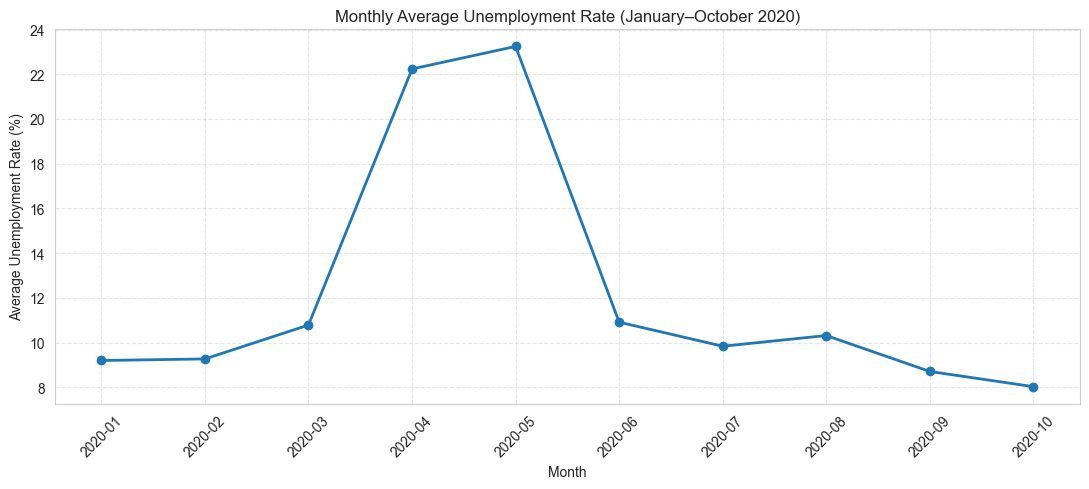

In [34]:

# Visualize the monthly unemployment trend

plt.figure(figsize=(11, 5))

plt.plot(
    monthly_summary.index,
    monthly_summary["Estimated Unemployment Rate (%)"],
    marker="o",
    linewidth=2
)

plt.title("Monthly Average Unemployment Rate (January–October 2020)")
plt.xlabel("Month")
plt.ylabel("Average Unemployment Rate (%)")
plt.xticks(rotation=45)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()



### 6.2 Regional Unemployment Comparison

This analysis compares average unemployment rates across regions in the supplementary dataset. It identifies the regions with the highest and lowest averages and displays the ten regions with the highest average unemployment rates.


In [35]:

# Calculate average unemployment by region

regional_summary_extra = (
    df_extra.groupby("Region")["Estimated Unemployment Rate (%)"]
    .mean()
    .sort_values(ascending=False)
)

print("Average unemployment rate by region:")
display(regional_summary_extra.round(2).to_frame())

print("\nTen regions with the highest average unemployment:")
display(regional_summary_extra.head(10).round(2).to_frame())

print("\nRegion with the highest average unemployment:")
print(
    f"{regional_summary_extra.idxmax()}: "
    f"{regional_summary_extra.max():.2f}%"
)

print("\nRegion with the lowest average unemployment:")
print(
    f"{regional_summary_extra.idxmin()}: "
    f"{regional_summary_extra.min():.2f}%"
)


Average unemployment rate by region:


,Estimated Unemployment Rate (%)
Region,
Haryana,27.48
Tripura,25.06
Jharkhand,19.54
Bihar,19.47
Delhi,18.41
Puducherry,17.94
Jammu & Kashmir,16.48
Himachal Pradesh,16.07
Rajasthan,15.87



Ten regions with the highest average unemployment:


,Estimated Unemployment Rate (%)
Region,
Haryana,27.48
Tripura,25.06
Jharkhand,19.54
Bihar,19.47
Delhi,18.41
Puducherry,17.94
Jammu & Kashmir,16.48
Himachal Pradesh,16.07
Rajasthan,15.87



Region with the highest average unemployment:
Haryana: 27.48%

Region with the lowest average unemployment:
Meghalaya: 3.87%


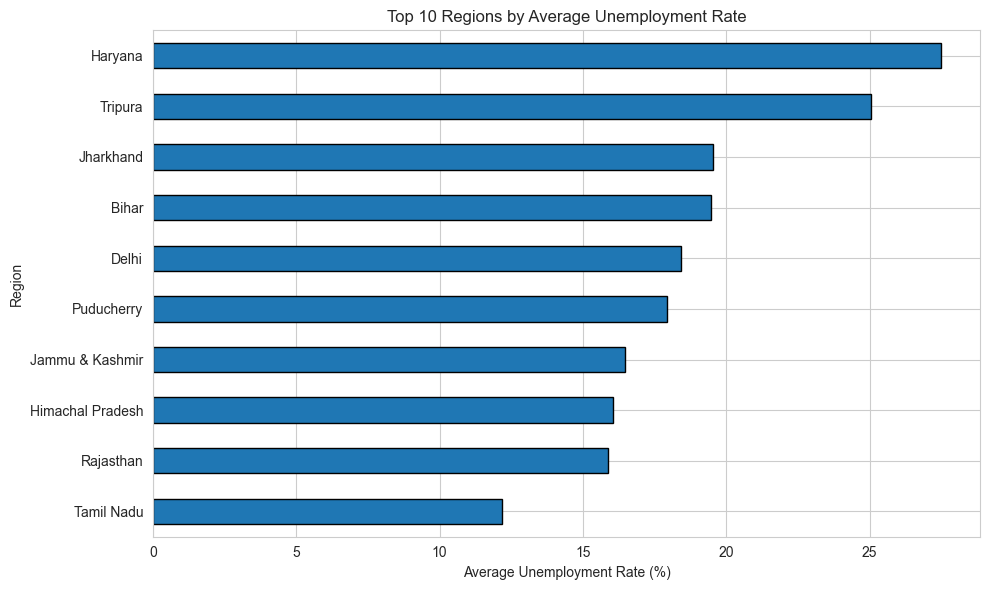

In [36]:

# Plot the ten regions with the highest average unemployment

top_10_extra = regional_summary_extra.head(10).sort_values()

plt.figure(figsize=(10, 6))

top_10_extra.plot(kind="barh", edgecolor="black")

plt.title("Top 10 Regions by Average Unemployment Rate")
plt.xlabel("Average Unemployment Rate (%)")
plt.ylabel("Region")
plt.tight_layout()
plt.show()



### 6.3 Geographic Distribution of Unemployment

The supplementary dataset includes latitude and longitude coordinates for its regions. This section compares regional average unemployment rates and displays their geographic locations using a scatter plot.

The visualization provides a geographic overview of the regional estimates. It is not a detailed administrative boundary map, and the coordinates represent approximate regional locations.


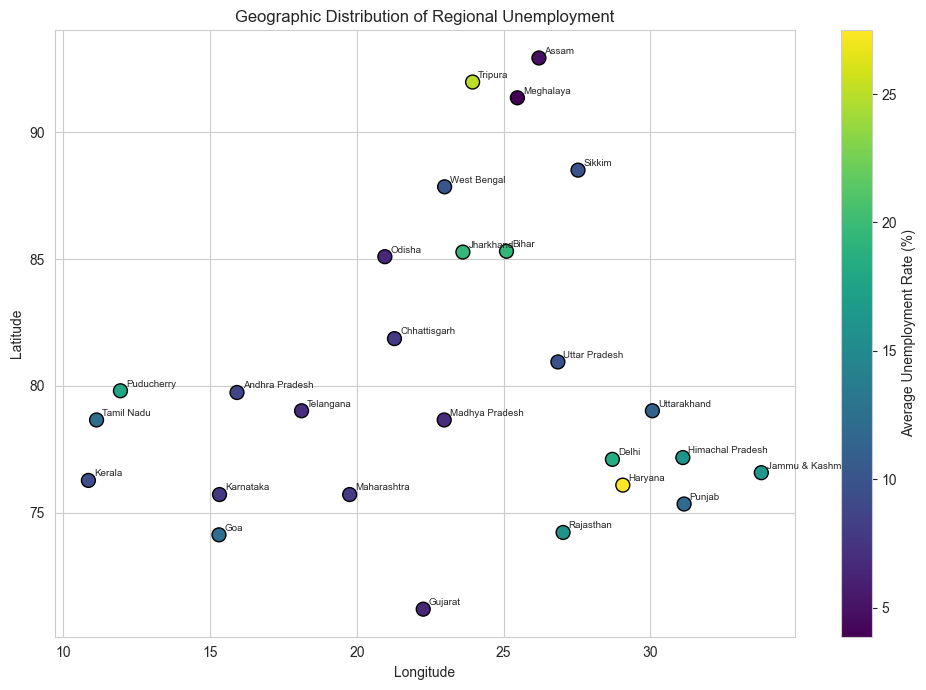

Number of regions displayed: 27


In [37]:

# Calculate average unemployment and coordinates by region

geographic_summary = (
    df_extra.groupby("Region")
    .agg({
        "Estimated Unemployment Rate (%)": "mean",
        "longitude": "mean",
        "latitude": "mean"
    })
    .reset_index()
)

plt.figure(figsize=(10, 7))

scatter = plt.scatter(
    geographic_summary["longitude"],
    geographic_summary["latitude"],
    c=geographic_summary["Estimated Unemployment Rate (%)"],
    s=100,
    cmap="viridis",
    edgecolors="black"
)

plt.colorbar(
    scatter,
    label="Average Unemployment Rate (%)"
)

for _, row in geographic_summary.iterrows():
    plt.annotate(
        row["Region"],
        (row["longitude"], row["latitude"]),
        xytext=(4, 3),
        textcoords="offset points",
        fontsize=7
    )

plt.title("Geographic Distribution of Regional Unemployment")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.tight_layout()
plt.show()

print("Number of regions displayed:", len(geographic_summary))


In [38]:

# Calculate month-to-month changes in average unemployment

monthly_change = monthly_summary[
    "Estimated Unemployment Rate (%)"
].diff()

monthly_change_summary = pd.DataFrame({
    "Average Unemployment Rate (%)": monthly_summary[
        "Estimated Unemployment Rate (%)"
    ],
    "Change from Previous Month (percentage points)": monthly_change
})

print("Monthly unemployment rates and changes:")
display(monthly_change_summary.round(2))

largest_increase_month = monthly_change.idxmax()
largest_decrease_month = monthly_change.idxmin()

print(
    "\nLargest month-to-month increase:",
    f"{monthly_change.loc[largest_increase_month]:.2f} percentage points",
    f"in {largest_increase_month}"
)

print(
    "Largest month-to-month decrease:",
    f"{monthly_change.loc[largest_decrease_month]:.2f} percentage points",
    f"in {largest_decrease_month}"
)


Monthly unemployment rates and changes:


,Average Unemployment Rate (%),Change from Previous Month (percentage points)
Date,,
2020-01,9.20,NaN
2020-02,9.27,0.07
2020-03,10.78,1.52
2020-04,22.24,11.45
2020-05,23.24,1.01
2020-06,10.91,-12.33
2020-07,9.83,-1.08
2020-08,10.31,0.48
2020-09,8.71,-1.61



Largest month-to-month increase: 11.45 percentage points in 2020-04
Largest month-to-month decrease: -12.33 percentage points in 2020-06


In [39]:

# Final validation of the supplementary dataset

print("FINAL SUPPLEMENTARY DATASET CHECK")
print("-" * 40)

print("Dataset shape:", df_extra.shape)
print("Unique regions:", df_extra["Region"].nunique())
print("Date range:", df_extra["Date"].min().date(), "to", df_extra["Date"].max().date())

print("\nMissing values:", df_extra.isnull().sum().sum())
print("Duplicate rows:", df_extra.duplicated().sum())
print("Invalid dates:", df_extra["Date"].isnull().sum())

print("\nColumns:")
print(df_extra.columns.tolist())


FINAL SUPPLEMENTARY DATASET CHECK
----------------------------------------
Dataset shape: (267, 9)
Unique regions: 27
Date range: 2020-01-31 to 2020-10-31

Missing values: 0
Duplicate rows: 0
Invalid dates: 0

Columns:
['Region', 'Date', 'Frequency', 'Estimated Unemployment Rate (%)', 'Estimated Employed', 'Estimated Labour Participation Rate (%)', 'Region.1', 'longitude', 'latitude']



### Supplementary Analysis — Observations and Conclusion

#### Dataset Overview

- The supplementary dataset contains **267 observations across 27 regions**, covering January to October 2020.
- The dataset contains no missing values, duplicate rows, or invalid dates. All 267 observations were retained after cleaning.
- The additional geographic coordinates allow regional unemployment estimates to be displayed spatially, providing another way to explore regional differences.

#### Monthly Unemployment Trends

- The average unemployment rate increased from **9.20% in January 2020 to 23.24% in May 2020**, the highest monthly average in this dataset.
- The largest month-to-month increase occurred in April 2020, when the average unemployment rate rose by **11.45 percentage points**, from 10.78% in March to 22.24% in April.
- The largest month-to-month decrease occurred in June 2020, when the average fell by **12.33 percentage points**, from 23.24% in May to 10.91% in June.
- By October 2020, the average unemployment rate had declined to **8.03%**, the lowest monthly average in the period examined.

#### Regional Differences

- Haryana recorded the highest average unemployment rate across the supplementary dataset at **27.48%**, followed by Tripura at 25.06%.
- Meghalaya recorded the lowest regional average at **3.87%**.
- The regional results demonstrate that unemployment rates varied considerably across the 27 regions during the period studied.

#### Conclusion

The supplementary analysis reveals a sharp increase in unemployment during April and May 2020, followed by a substantial decline in June and a further decrease by October. Regional comparisons also show considerable variation in average unemployment across the country.

The results provide additional insight into unemployment trends during the early months of the COVID-19 pandemic. However, the analysis is descriptive and does not independently establish the causes of the observed changes.

**Dataset limitation:** The supplementary dataset contains regional estimates that differ from the area-level observations in the original dataset. Therefore, the two datasets were analyzed separately rather than directly combined. Their results should not be treated as one continuous, directly comparable series without further validation.
